# UCI Cleveland Heart Disease: Multi-Class Modeling & Evaluation
## Phase 1: Multi-Class Data Preprocessing & Exploratory Analysis

### Overview:
This notebook implements an end-to-end machine learning pipeline for **multi-class coronary artery disease (CAD) severity classification** using the gold-standard **UCI Cleveland Heart Disease dataset**.

Unlike conventional binary studies that collapse all stages of disease into 0 vs 1, this study preserves the **5 clinical severity tiers** (0 = No disease, 1 = Mild CAD, 2 = Moderate CAD, 3 = Severe CAD, 4 = Critical CAD).

### Phase 1 Focus Areas:
1. **Schema & Header Mapping**: Loading all 303 patient records with standardized clinical attribute names.
2. **Target Multi-Class Preservation**: Retaining the 5 angiographic disease severity levels (0, 1, 2, 3, 4).
3. **Multi-Class EDA & Visualization**: Analyzing feature shifts across progressive severity grades.
4. **Zero-Leakage Preprocessing Protocol**:
   - Stratified 80/20 train/test split executed **prior** to any data transformations.
   - Missing value imputation (median for numerical, mode for categorical) fitted strictly on `X_train`.
   - One-Hot Encoding for nominal clinical predictors (`cp`, `restecg`, `slope`, `thal`) fitted strictly on `X_train`.
   - Min-Max scaling to [0, 1] fitted strictly on `X_train`.
   - Multi-class SMOTE balancing (k=3) applied **exclusively on the training split** (class 4 has only 10 training samples).
5. **Preparation for Phase 2**: Verification of clean, preprocessed feature matrices ready for Logistic Regression, SVM, Random Forest, and a lightweight Neural Network.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler
from imblearn.over_sampling import SMOTE

# Plot styling
%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.autolayout'] = True

## 1. Dataset Ingestion & Schema Mapping

The Cleveland dataset contains 13 clinical attributes and 1 angiographic target attribute across 303 patient records. Missing values are encoded as `?` in the raw file.

In [2]:
# Standard clinical feature schema
COLUMNS = [
    'age',       # Age in years (Continuous)
    'sex',       # Sex: 1 = Male, 0 = Female (Binary)
    'cp',        # Chest pain type (Nominal: 1: typ angina, 2: atyp angina, 3: non-anginal, 4: asympt)
    'trestbps',  # Resting blood pressure in mm Hg (Continuous)
    'chol',      # Serum cholesterol in mg/dl (Continuous)
    'fbs',       # Fasting blood sugar > 120 mg/dl: 1 = true, 0 = false (Binary)
    'restecg',   # Resting ECG (Nominal: 0: normal, 1: ST-T wave abn, 2: LV hypertrophy)
    'thalach',   # Maximum heart rate achieved (Continuous)
    'exang',     # Exercise induced angina: 1 = yes, 0 = no (Binary)
    'oldpeak',   # ST depression induced by exercise relative to rest (Continuous)
    'slope',     # Slope of peak exercise ST segment (Ordered: 1: up, 2: flat, 3: down)
    'ca',        # Number of major vessels (0-3) colored by fluoroscopy (Count/Continuous)
    'thal',      # Thallium scan: 3 = normal, 6 = fixed defect, 7 = reversible defect (Nominal)
    'target'     # Angiographic CAD severity: 0 = No disease, 1 = Mild, 2 = Moderate, 3 = Severe, 4 = Critical
]

data_path = 'datasets/heart+disease/processed.cleveland.data'
df = pd.read_csv(data_path, header=None, names=COLUMNS, na_values='?')

print(f"Dataset successfully loaded: {df.shape[0]} rows, {df.shape[1]} columns")
df.head()

Dataset successfully loaded: 303 rows, 14 columns


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


## 2. Multi-Class Severity Target Distribution

The target attribute `target` measures coronary artery stenosis:
- **Class 0**: Normal (<50% diameter narrowing) – No significant CAD
- **Class 1**: Mild CAD (>50% narrowing in 1 major vessel branch)
- **Class 2**: Moderate CAD
- **Class 3**: Severe CAD
- **Class 4**: Critical CAD (Extensive multi-vessel occlusion)

Unlike balanced binary formulations, this multi-class spectrum is naturally imbalanced.

,Severity Grade,Patient Count,Percentage (%)
0,Class 0 (No Disease),164,54.13
1,Class 1 (Mild CAD),55,18.15
2,Class 2 (Moderate CAD),36,11.88
3,Class 3 (Severe CAD),35,11.55
4,Class 4 (Critical CAD),13,4.29


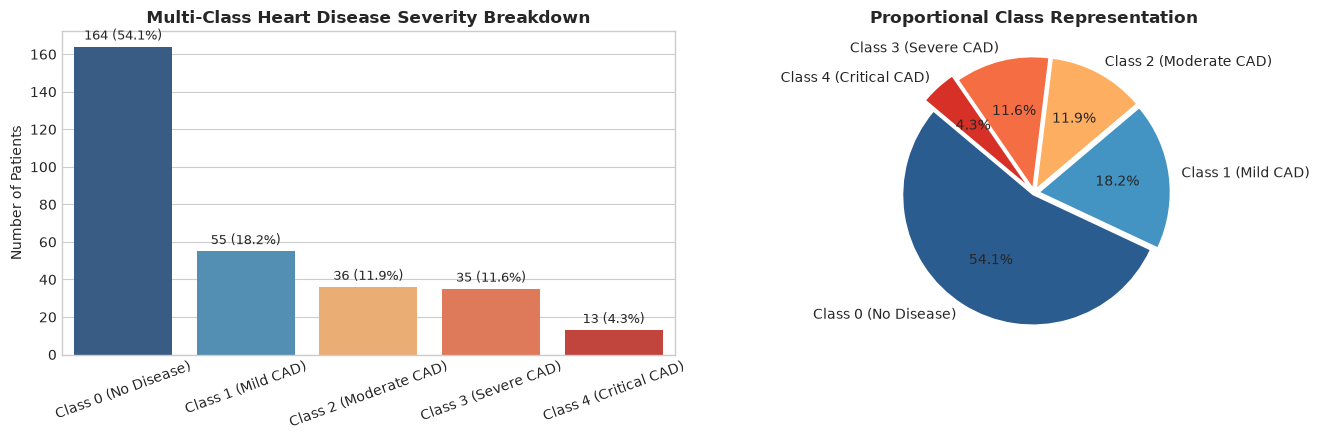

In [3]:
severity_labels = {
    0: 'Class 0 (No Disease)',
    1: 'Class 1 (Mild CAD)',
    2: 'Class 2 (Moderate CAD)',
    3: 'Class 3 (Severe CAD)',
    4: 'Class 4 (Critical CAD)'
}

target_counts = df['target'].value_counts().sort_index()
target_pcts = df['target'].value_counts(normalize=True).sort_index() * 100

dist_df = pd.DataFrame({
    'Severity Grade': [severity_labels[i] for i in target_counts.index],
    'Patient Count': target_counts.values,
    'Percentage (%)': target_pcts.round(2).values
})
display(dist_df)

# Visualize Class Distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
palette = ['#2b5c8f', '#4393c3', '#fdae61', '#f46d43', '#d73027']

sns.barplot(x=list(severity_labels.values()), y=target_counts.values, hue=list(severity_labels.values()), palette=palette, legend=False, ax=axes[0])
axes[0].set_title('Multi-Class Heart Disease Severity Breakdown', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Number of Patients')
axes[0].tick_params(axis='x', rotation=20)
for p in axes[0].patches:
    val = int(p.get_height())
    pct = p.get_height() / len(df) * 100
    axes[0].annotate(f"{val} ({pct:.1f}%)", 
                     (p.get_x() + p.get_width() / 2., p.get_height()), 
                     ha='center', va='bottom', fontsize=9, xytext=(0, 3), textcoords='offset points')

axes[1].pie(target_counts.values, labels=list(severity_labels.values()), autopct='%1.1f%%', 
            colors=palette, startangle=140, explode=[0.02, 0.05, 0.05, 0.05, 0.1])
axes[1].set_title('Proportional Class Representation', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

## 3. Missing Value Analysis
We inspect missing entries across all 14 clinical features.

In [4]:
missing_info = df.isna().sum()
missing_cols = missing_info[missing_info > 0]
print('Missing Value Summary:')
for col, cnt in missing_cols.items():
    pct = cnt / len(df) * 100
    print(f"- {col:15s}: {cnt} missing values ({pct:.2f}% of dataset)")

print('\nImputation Strategy:')
print("- 'ca' (fluoroscopy count, 4 missing): Median Imputation")
print("- 'thal' (thallium scan, 2 missing): Mode (Most Frequent) Imputation")

Missing Value Summary:
- ca             : 4 missing values (1.32% of dataset)
- thal           : 2 missing values (0.66% of dataset)

Imputation Strategy:
- 'ca' (fluoroscopy count, 4 missing): Median Imputation
- 'thal' (thallium scan, 2 missing): Mode (Most Frequent) Imputation


## 4. Multi-Class Exploratory Data Analysis & Feature Shifts

Examining how clinical measurements vary as CAD progresses from Class 0 (Healthy) to Class 4 (Critical).

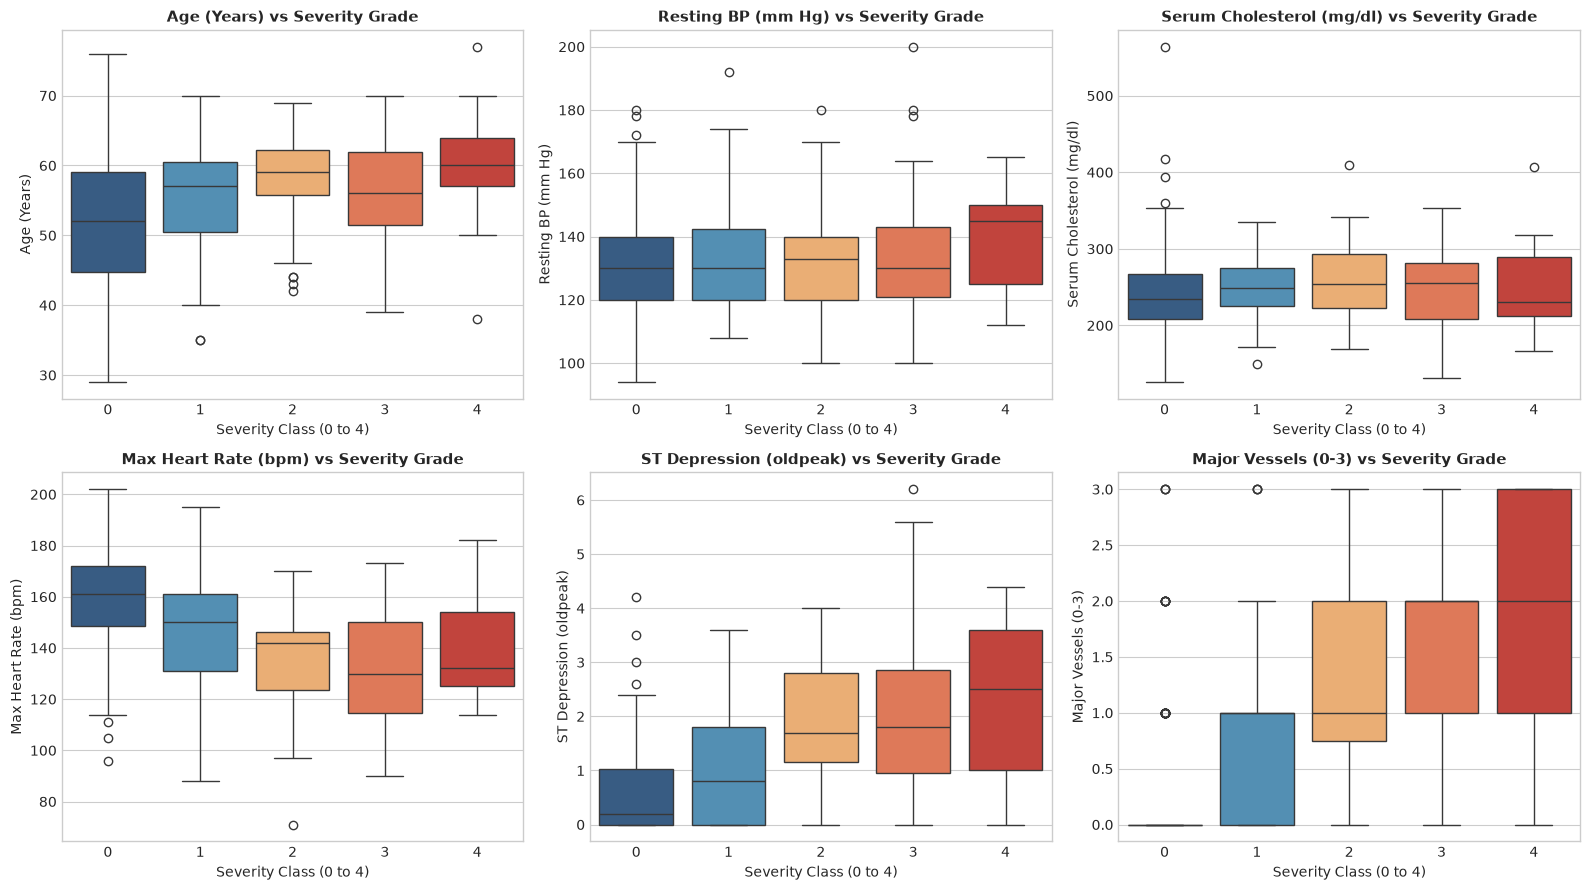

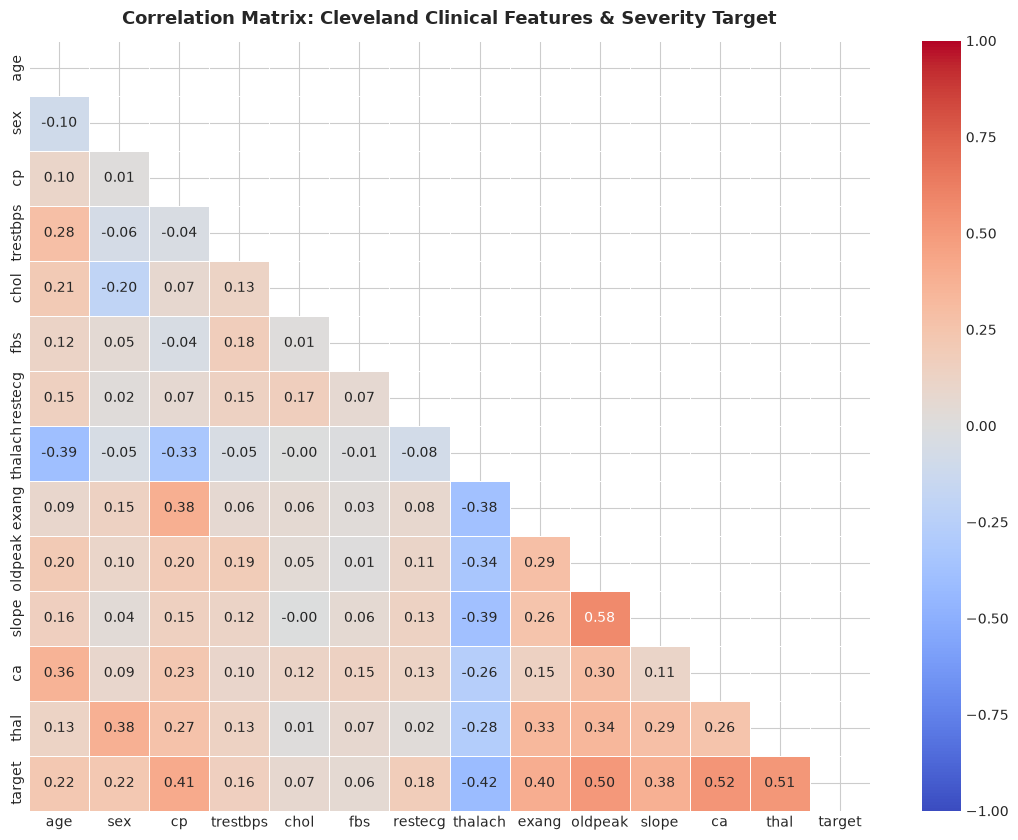

In [5]:
# Continuous features across severity levels
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
continuous_cols = [
    ('age', 'Age (Years)'),
    ('trestbps', 'Resting BP (mm Hg)'),
    ('chol', 'Serum Cholesterol (mg/dl)'),
    ('thalach', 'Max Heart Rate (bpm)'),
    ('oldpeak', 'ST Depression (oldpeak)'),
    ('ca', 'Major Vessels (0-3)')
]

for idx, (col, label) in enumerate(continuous_cols):
    ax = axes[idx // 3, idx % 3]
    sns.boxplot(x='target', y=col, data=df, hue='target', palette=palette, legend=False, ax=ax)
    ax.set_title(f"{label} vs Severity Grade", fontsize=11, fontweight='bold')
    ax.set_xlabel('Severity Class (0 to 4)')
    ax.set_ylabel(label)

plt.tight_layout()
plt.show()

# Correlation Heatmap
plt.figure(figsize=(11, 8.5))
corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', mask=mask, vmin=-1, vmax=1, linewidths=0.5)
plt.title('Correlation Matrix: Cleveland Clinical Features & Severity Target', fontsize=13, fontweight='bold', pad=12)
plt.show()

## 5. Zero-Leakage Preprocessing Pipeline

To prevent data leakage:
1. **Stratified Split**: 80% train / 20% test preserving the 5-class distribution.
2. **Imputation**: Median/Mode fitted on `X_train`, applied to `X_test`.
3. **One-Hot Encoding**: Fitted on `X_train` for nominal features (`cp`, `restecg`, `slope`, `thal`).
4. **Min-Max Scaling**: [0, 1] normalization fitted on `X_train`.
5. **SMOTE Balancing**: Multi-class SMOTE with k=3 applied **strictly on `X_train`** (class 4 has 10 samples in train, so k <= 9; k=3 ensures stable local interpolation).

In [7]:
# 1. Feature-Target Separation & Stratified Split
X = df.drop(columns=['target'])
y = df['target'].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print('=== TRAIN-TEST SPLIT SUMMARY ===')
print(f"Training set samples: {len(X_train)} ({len(X_train)/len(df)*100:.1f}%)")
print(f"Holdout test samples:  {len(X_test)} ({len(X_test)/len(df)*100:.1f}%)")
print('\nClass counts in Train:', y_train.value_counts().sort_index().to_dict())
print('Class counts in Test: ', y_test.value_counts().sort_index().to_dict())

# Column categories
num_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'ca']
cat_cols = ['cp', 'restecg', 'slope', 'thal']
bin_cols = ['sex', 'fbs', 'exang']

# 2. Leak-Free Missing Value Imputation
num_imputer = SimpleImputer(strategy='median')
cat_imputer = SimpleImputer(strategy='most_frequent')

X_tr_num = pd.DataFrame(num_imputer.fit_transform(X_train[num_cols]), columns=num_cols, index=X_train.index)
X_te_num = pd.DataFrame(num_imputer.transform(X_test[num_cols]), columns=num_cols, index=X_test.index)

X_tr_cat_all = pd.DataFrame(cat_imputer.fit_transform(X_train[cat_cols + bin_cols]), columns=cat_cols + bin_cols, index=X_train.index)
X_te_cat_all = pd.DataFrame(cat_imputer.transform(X_test[cat_cols + bin_cols]), columns=cat_cols + bin_cols, index=X_test.index)

# 3. One-Hot Encoding for Nominal Categorical Features
ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
ohe_cols = ohe.fit(X_tr_cat_all[cat_cols]).get_feature_names_out(cat_cols)

X_tr_ohe = pd.DataFrame(ohe.transform(X_tr_cat_all[cat_cols]), columns=ohe_cols, index=X_train.index)
X_te_ohe = pd.DataFrame(ohe.transform(X_te_cat_all[cat_cols]), columns=ohe_cols, index=X_test.index)

# Assemble Full Feature Matrices
X_tr_assembled = pd.concat([X_tr_num, X_tr_cat_all[bin_cols], X_tr_ohe], axis=1)
X_te_assembled = pd.concat([X_te_num, X_te_cat_all[bin_cols], X_te_ohe], axis=1)

# 4. Min-Max Scaling to [0, 1]
scaler = MinMaxScaler()
final_feature_names = X_tr_assembled.columns
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_tr_assembled), columns=final_feature_names, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_te_assembled), columns=final_feature_names, index=X_test.index)

# 5. Multi-Class SMOTE (Train Set Only)
smote = SMOTE(k_neighbors=3, random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_scaled, y_train)
X_train_final = pd.DataFrame(X_train_resampled, columns=final_feature_names)
y_train_final = pd.Series(y_train_resampled, name='target')

print('\n' + '='*65)
print('PREPROCESSING PIPELINE EXECUTION COMPLETED')
print('='*65)
print(f"X_train post-SMOTE shape: {X_train_final.shape} | Class balance: {y_train_final.value_counts().sort_index().to_dict()}")
print(f"X_test (untouched) shape: {X_test_scaled.shape}  | Class balance: {y_test.value_counts().sort_index().to_dict()}")
print(f"Total Transformed Clinical Feature Dimensions: {len(final_feature_names)}")
print('Transformed Feature Columns:', list(final_feature_names))

=== TRAIN-TEST SPLIT SUMMARY ===
Training set samples: 242 (79.9%)
Holdout test samples:  61 (20.1%)

Class counts in Train: {0: 131, 1: 44, 2: 29, 3: 28, 4: 10}
Class counts in Test:  {0: 33, 1: 11, 2: 7, 3: 7, 4: 3}

PREPROCESSING PIPELINE EXECUTION COMPLETED
X_train post-SMOTE shape: (655, 22) | Class balance: {0: 131, 1: 131, 2: 131, 3: 131, 4: 131}
X_test (untouched) shape: (61, 22)  | Class balance: {0: 33, 1: 11, 2: 7, 3: 7, 4: 3}
Total Transformed Clinical Feature Dimensions: 22
Transformed Feature Columns: ['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'ca', 'sex', 'fbs', 'exang', 'cp_1.0', 'cp_2.0', 'cp_3.0', 'cp_4.0', 'restecg_0.0', 'restecg_1.0', 'restecg_2.0', 'slope_1.0', 'slope_2.0', 'slope_3.0', 'thal_3.0', 'thal_6.0', 'thal_7.0']


## 6. Preprocessed Feature Matrices Inspection
Previewing the first 5 records of the clean, scaled, balanced training matrix.

In [8]:
X_train_final.head()

,age,trestbps,chol,thalach,oldpeak,ca,sex,fbs,exang,cp_1.0,...,cp_4.0,restecg_0.0,restecg_1.0,restecg_2.0,slope_1.0,slope_2.0,slope_3.0,thal_3.0,thal_6.0,thal_7.0
0,0.645833,0.528302,0.301370,0.656489,0.419355,0.666667,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
1,0.208333,0.433962,0.445205,0.847328,0.000000,0.000000,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0
2,0.520833,0.358491,0.369863,0.671756,0.000000,0.333333,0.0,1.0,1.0,0.0,...,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0
3,0.562500,0.339623,0.216895,0.702290,0.000000,0.000000,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0
4,0.791667,0.292453,0.292237,0.702290,0.032258,0.666667,1.0,1.0,0.0,0.0,...,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0


## Phase 1 Deliverables Summary

| Component | Train (Preprocessed + SMOTE) | Holdout Test (Untouched) |
|:---|:---:|:---:|
| **Samples** | 655 (131 per class) | 61 (natural severity distribution) |
| **Feature Count** | 22 (scaled to [0, 1]) | 22 (scaled to [0, 1]) |
| **Missing Values** | 0 | 0 |
| **Data Leakage Risk** | **Zero** (Imputers, Encoders, Scaler fitted on Train only) | Pristine validation set |

The preprocessed datasets `X_train_final`, `y_train_final`, `X_test_scaled`, and `y_test` are ready for **Phase 2: Baseline and Advanced Model Training** (Logistic Regression, SVM, Random Forest, Neural Network).